In [2]:
import cv2 as cv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import skimage as ski

import numpy.ma as ma
# import cupy as cp

import scipy as sp

import statistics as st

from itertools import cycle

# from sklearn.preprocessing import minmax_scale
import pandas as pd

from scipy import ndimage as ndi
from skimage.feature import peak_local_max

In [3]:
matplotlib.rcParams['figure.dpi'] = 200
matplotlib.rcParams['figure.figsize'] = [6.4, 4.9]

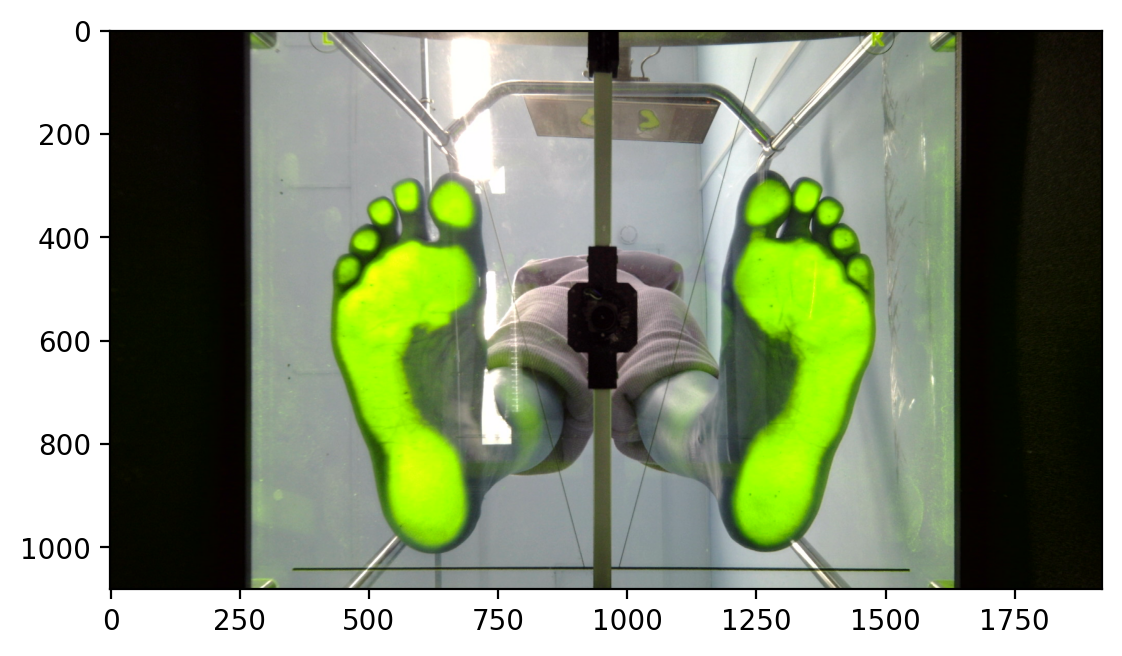

In [4]:
image = cv.imread("./плантограммы/Img (copy 7).png")

plt.imshow(image)

In [5]:
def split_foot(image):
    leftPad = 280
    rightPad = 1920 - 1630
    yPad = 50
    assert image.shape == (1080, 1920, 3)
    return image[yPad:,leftPad:880,:], image[yPad:,1025:-rightPad,:]


(1030, 600, 3) (1030, 605, 3)


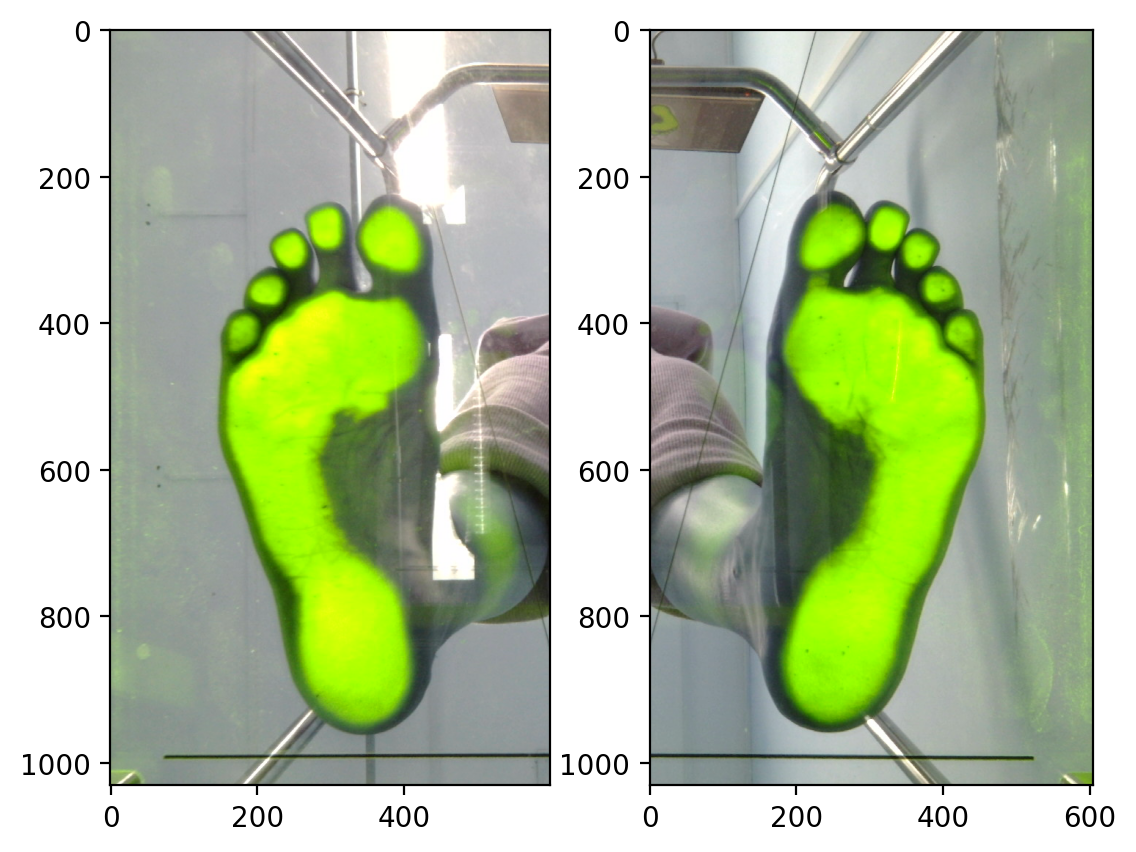

In [6]:
footL, footR = split_foot(image)
fig, (ax1, ax2) = plt.subplots(1, 2)
ax1.imshow(footL)
ax2.imshow(footR)
# ax1.grid(which='major')
# ax1.set_yticks(np.linspace(0, 1100, 65), )
print(footL.shape, footR.shape)

130.0


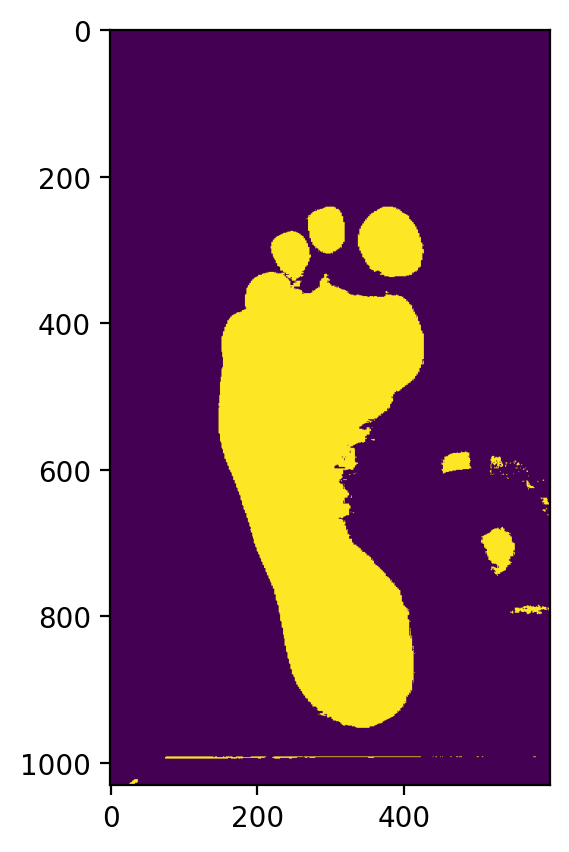

In [7]:
hsv = cv.cvtColor(footL, cv.COLOR_RGB2HSV)

V = hsv[...,2]
S = hsv[...,1]


retval, binS = cv.threshold(S, 0, 255, cv.THRESH_OTSU)
print(retval)

plt.imshow(binS)

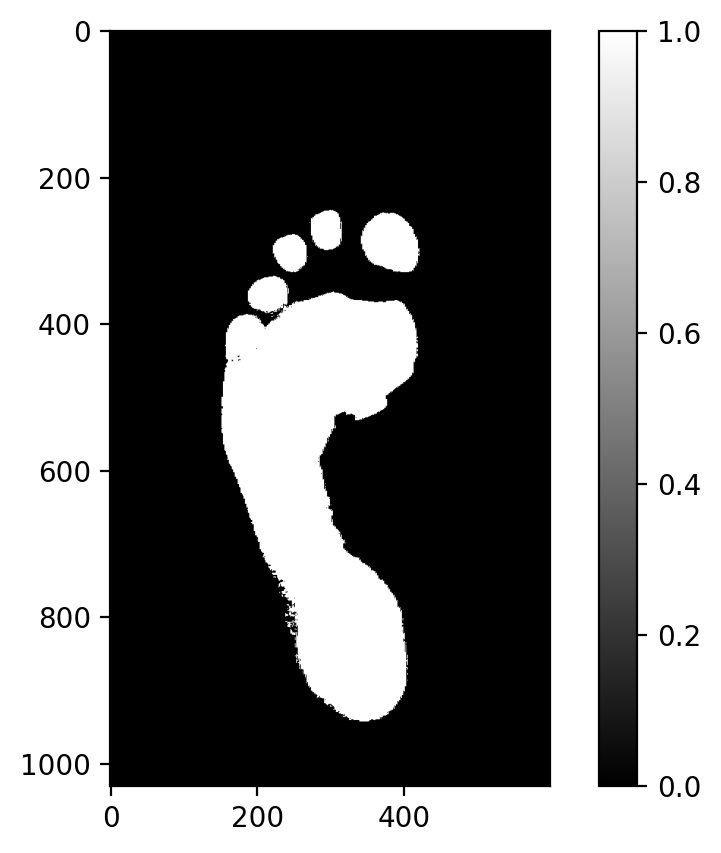

In [8]:
hsv = cv.cvtColor(footL, cv.COLOR_RGB2HSV)

V = hsv[...,2]
S = hsv[...,1]
mask = S > 230
V[~mask] = 0 
plt.imshow(mask, 'gray')
plt.colorbar()

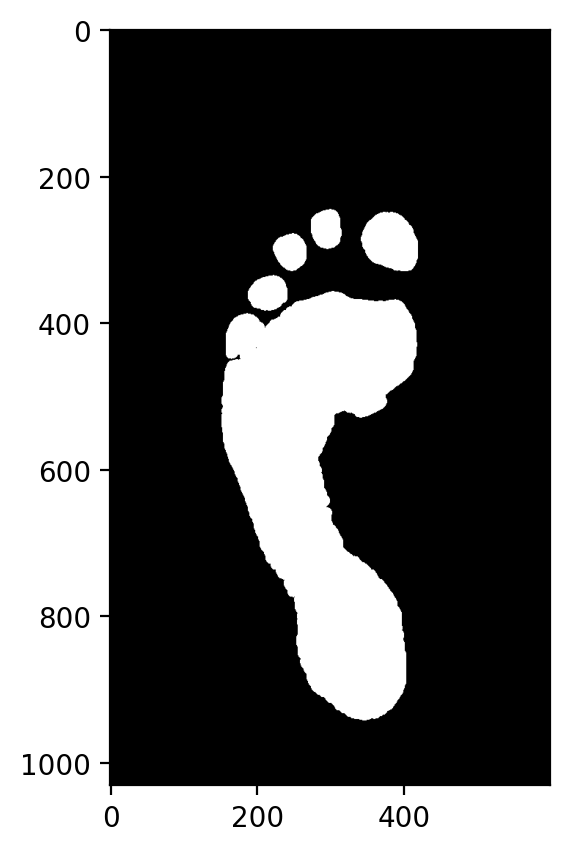

In [9]:
ksize = 15

kernelEllipse = cv.getStructuringElement(cv.MORPH_ELLIPSE,(ksize, ksize))
# kernelRect = cv.getStructuringElement(cv.MORPH_RECT,(ksize, ksize))

openingEllipse1 = cv.morphologyEx(np.asarray(mask, np.uint8), cv.MORPH_OPEN, kernelEllipse)

plt.imshow(openingEllipse1, 'gray')

(1030, 600) int32


[ WARN:0@5.319] global loadsave.cpp:1089 imwrite_ Unsupported depth image for selected encoder is fallbacked to CV_8U.


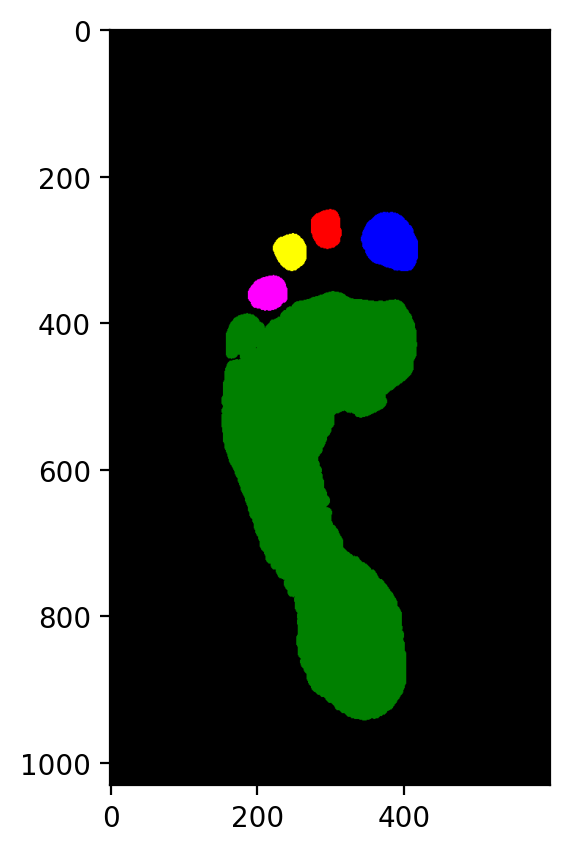

In [10]:
retval, labels = cv.connectedComponents(openingEllipse1, connectivity=4, ltype=cv.CV_32S)

# labels = labels + 1
print(labels.shape, labels.dtype)

# colorLabels = ski.color.label2rgb(labels,)
# print(colorLabels.shape, colorLabels.dtype)

cv.imwrite('./markers-7.png', labels)
cv.imwrite('./7-footL.png', footL)

plt.imshow(ski.color.label2rgb(labels))

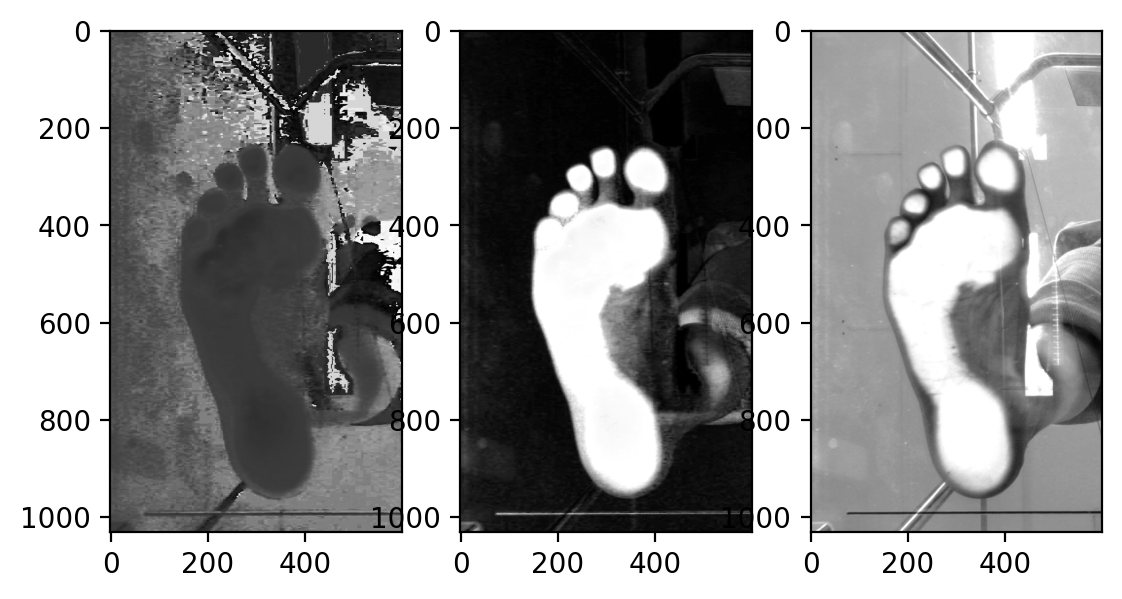

In [11]:
fig, axs = plt.subplots(1,3)

hsv = cv.cvtColor(footL, cv.COLOR_RGB2HSV)

axs[0].imshow(hsv[...,0], 'gray')
axs[1].imshow(hsv[...,1], 'gray')
axs[2].imshow(hsv[...,2], 'gray')



In [13]:
V = hsv[...,2]
newLabels = cv.watershed(, labels)

plt.imshow(ski.color.label2rgb(newLabels))

SyntaxError: invalid syntax (361879904.py, line 2)

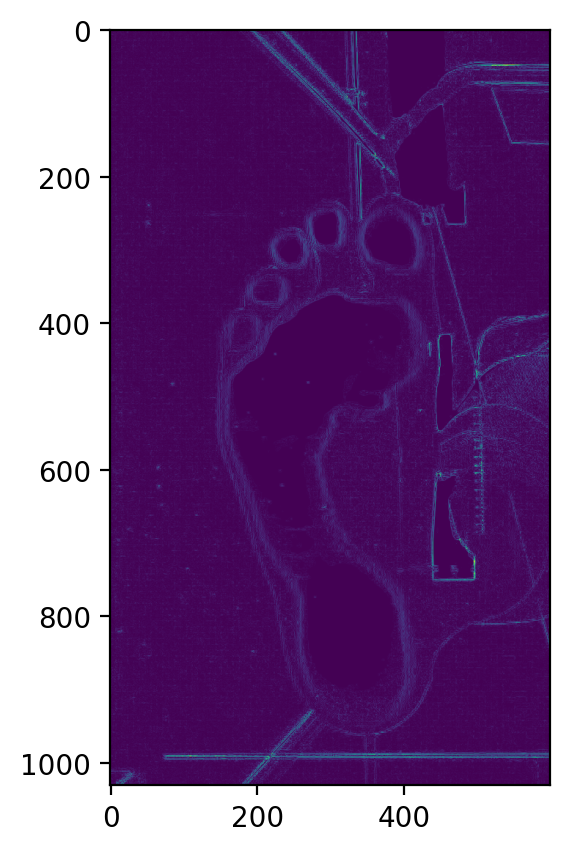

In [16]:

gradient = cv.Laplacian(hsv, 3, ksize=3)


# print(gradient.shape, gradient.dtype)

cv.normalize(np.abs(gradient), gradient, alpha=0, beta=255, norm_type=cv.NORM_MINMAX)

gradient = gradient.astype(np.uint8)

plt.imshow(gradient[...,2])